# Многомерни данни и извадъчна геометрия

Използваме данните за червено вино от предходното упражнение. Файлът `winequality_red.csv` трябва да е в подпапка `data`.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"


plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'figure.dpi': 110,
})

blue = '#2563eb'
orange = '#ea580c'
teal = '#0f766e'
gray = '#64748b'

## 1. Матрица на данните

Нека $x_{ij}$ е стойността на $j$-тата променлива за $i$-тото вино. Матрицата на данните е $X=(x_{ij})\in\mathbb R^{n\times p}$. Редовете са наблюдения, а колоните са вектори от измервания. Средната стойност и извадъчното стандартно отклонение на колона $j$ са

$$\bar x_j=\frac1n\sum_{i=1}^n x_{ij},\qquad
s_j=\sqrt{\frac1{n-1}\sum_{i=1}^n(x_{ij}-\bar x_j)^2}.$$

**Задача 1а.** Заредете файла с разделител `;`, заменете интервалите в имената с `_` и оставете по един екземпляр от напълно еднаквите редове, както в предходното упражнение. Изберете `fixed_acidity`, `pH`, `density` и `alcohol`. Запишете таблицата като `data`, а числовата матрица като `X`. Определете $n,p$, средните стойности и стандартните отклонения.

In [21]:
# Задача 1а
data = pd.read_csv("data/winequality_red.csv",sep=';')
data = data.rename(columns=lambda c: re.sub(r"\s+", "_", c))
data = data.drop_duplicates()
data = data[["fixed_acidity","pH","density","alcohol"]]
data.mean()
data.var()

fixed_acidity     8.310596
pH                3.309787
density           0.996709
alcohol          10.432315
dtype: float64

fixed_acidity    3.017134
pH               0.024036
density          0.000003
alcohol          1.170866
dtype: float64

**Задача 1б. Визуализация.** Постройте матрица от scatterplots, с хистограми по диагонала. Може да използвате `pd.plotting.scatter_matrix`. Посочете двойки с положителна, отрицателна и слаба линейна връзка.

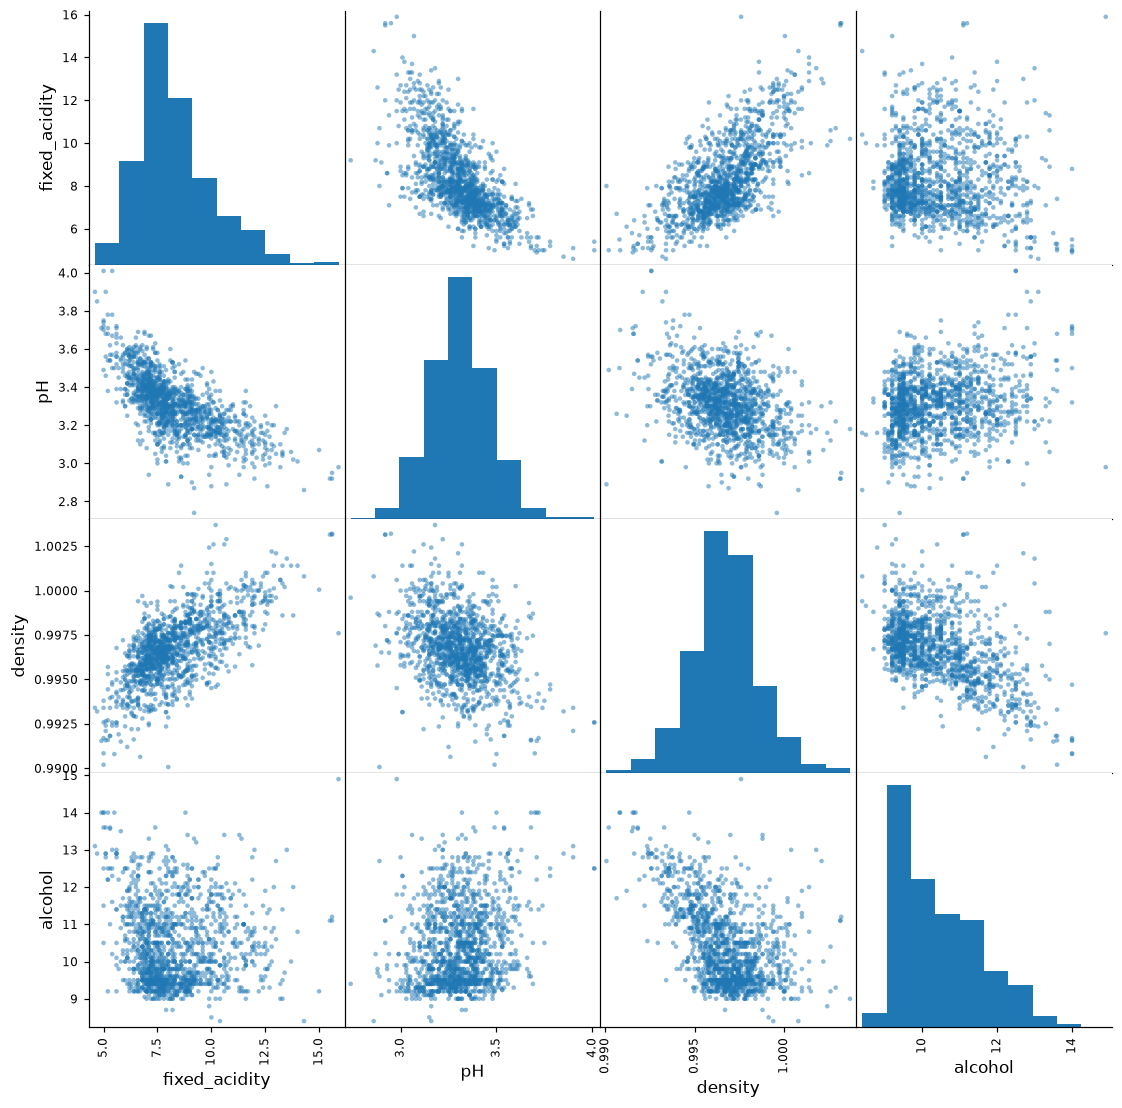

In [26]:
# Задача 1б
pd.plotting.scatter_matrix(data,figsize=(12,12));
plt.show();

## 2. Ковариационна и корелационна матрица

Центрираната матрица $Z$ има елементи $z_{ij}=x_{ij}-\bar x_j$. Ковариационната матрица $S=(s_{jk})$ и корелационната матрица $R=(r_{jk})$ се определят чрез

$$S=\frac{Z^\top Z}{n-1},\qquad
s_{jk}=\frac1{n-1}\sum_{i=1}^n z_{ij}z_{ik},\qquad
r_{jk}=\frac{s_{jk}}{s_js_k}.$$

Имаме $s_{jj}=s_j^2$ и $r_{jj}=1$. Корелацията е определена за колони с ненулево стандартно отклонение.

**Задача 2а.** Пресметнете $Z,S,R$ с NumPy. Проверете, че сумата на всяка колона на $Z$ е нула. Сравнете резултатите с `data.cov()` и `data.corr()`.

In [ ]:
# Задача 2а
Z = data-data.mean()
Z.sum()
S = pd.DataFrame(np.dot(Z.transpose(),Z)/(Z.shape[0]-1))
S
std = np.sqrt(np.diag(S))
std
np.outer(std,std)
R = S / np.outer(std, std)
R

S = data.cov();
S
R = data.corr();
R

fixed_acidity   -1.477929e-12
pH              -2.486900e-13
density          1.342260e-13
alcohol          2.273737e-13
dtype: float64

,0,1,2,3
0,3.017134,-0.184922,0.002176,-0.115772
1,-0.184922,0.024036,-0.000103,0.035803
2,0.002176,-0.000103,0.000003,-0.001021
3,-0.115772,0.035803,-0.001021,1.170866


array([1.73698981, 0.15503631, 0.00186892, 1.08206545])

array([[3.01713359e+00, 2.69296493e-01, 3.24629001e-03, 1.87953666e+00],
       [2.69296493e-01, 2.40362578e-02, 2.89750018e-04, 1.67759436e-01],
       [3.24629001e-03, 2.89750018e-04, 3.49285125e-06, 2.02229066e-03],
       [1.87953666e+00, 1.67759436e-01, 2.02229066e-03, 1.17086564e+00]])

array(4.21203898)

,0,1,2,3
0,1.000000,-0.686685,0.670195,-0.061596
1,-0.686685,1.000000,-0.355617,0.213418
2,0.670195,-0.355617,1.000000,-0.504995
3,-0.061596,0.213418,-0.504995,1.000000


,fixed_acidity,pH,density,alcohol
fixed_acidity,3.017134,-0.184922,0.002176,-0.115772
pH,-0.184922,0.024036,-0.000103,0.035803
density,0.002176,-0.000103,0.000003,-0.001021
alcohol,-0.115772,0.035803,-0.001021,1.170866


,fixed_acidity,pH,density,alcohol
fixed_acidity,1.000000,-0.686685,0.670195,-0.061596
pH,-0.686685,1.000000,-0.355617,0.213418
density,0.670195,-0.355617,1.000000,-0.504995
alcohol,-0.061596,0.213418,-0.504995,1.000000


**Задача 2б. Визуализация.** Начертайте $S$ и $R$ с цвят и стойността във всяка клетка. За $R$ използвайте цветна скала от $-1$ до $1$. Обяснете разликата между диагоналите на двете матрици.

<Axes: >

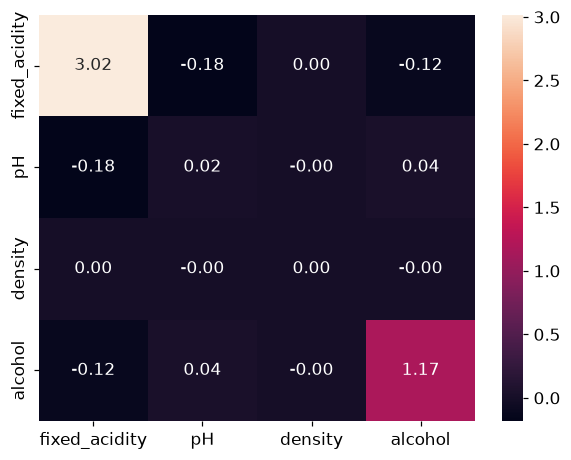

<Axes: >

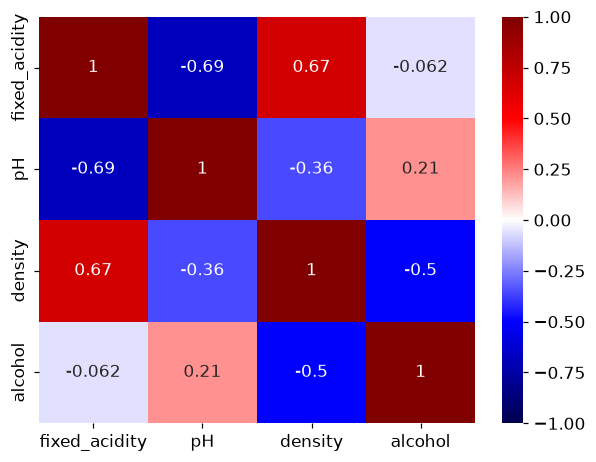

In [56]:
# Задача 2б
import seaborn as sns

sns.heatmap(S,annot=True,fmt=".2f");
plt.show()
sns.heatmap(R,vmin=-1,vmax=1,annot=True,cmap="seismic");
plt.show()

## 3. Проекции: пример с две наблюдения

За вектори $\mathbf a,\mathbf b\in\mathbb R^m$ скаларното произведение и евклидовата норма са

$$\mathbf a^\top\mathbf b=\sum_{i=1}^m a_ib_i,\qquad
\|\mathbf a\|=\sqrt{\mathbf a^\top\mathbf a}.$$

При $\mathbf a\ne\mathbf0$ ортогоналната проекция на $\mathbf x$ върху направлението на $\mathbf a$ е

$$\operatorname{proj}_{\mathbf a}\mathbf x
=\frac{\mathbf x^\top\mathbf a}{\mathbf a^\top\mathbf a}\mathbf a.$$

За вектор $\mathbf x=(x_1,\ldots,x_m)^\top$ и вектор $\mathbf1\in\mathbb R^m$ от единици дефинираме

$$\bar x=\frac1m\sum_{i=1}^m x_i,\quad
\mathbf q=\frac{\mathbf1}{\sqrt m},\quad
\mathbf d=\mathbf x-\bar x\mathbf1,\quad
\mathbf u=\frac{\mathbf d}{\|\mathbf d\|}.$$

Тогава $\|\mathbf q\|=\|\mathbf u\|=1$, $\mathbf q^\top\mathbf u=0$ и

$$\mathbf p_q=(\mathbf x^\top\mathbf q)\mathbf q=\bar x\mathbf1,
\qquad \mathbf p_u=(\mathbf x^\top\mathbf u)\mathbf u=\mathbf d,
\qquad \mathbf x=\mathbf p_q+\mathbf p_u.$$

**Задача 3а.** Използвайте първите две нвблюдения над фиксирана киселинност като двете координати на $\mathbf x$. В този пример $m=2$ и $\mathbf q=(1,1)^\top/\sqrt2$. Пресметнете $\mathbf q,\mathbf u,\mathbf p_q,\mathbf p_u$ и проверете равенствата.

In [111]:
# Задача 3а
vec = data["fixed_acidity"].head(2)
mean = vec.mean()
q = pd.Series([1,1])/np.sqrt(2)
d=vec-mean
u=d/np.sqrt(np.dot(d,d))
p_q = np.dot(np.dot(vec,q),q)
p_q
p_u = np.dot(np.dot(vec,u),u)
p_u
p_u + p_q
vec

array([7.6, 7.6])

array([-0.2,  0.2])

array([7.4, 7.8])

0    7.4
1    7.8
Name: fixed_acidity, dtype: float64

**Задача 3б. Визуализация.** Визуализираите векторите от предишната задача

(np.float64(-1.3558073580374335),
 np.float64(8.248700576850887),
 np.float64(-0.40125318653776126),
 np.float64(8.418538742699932))

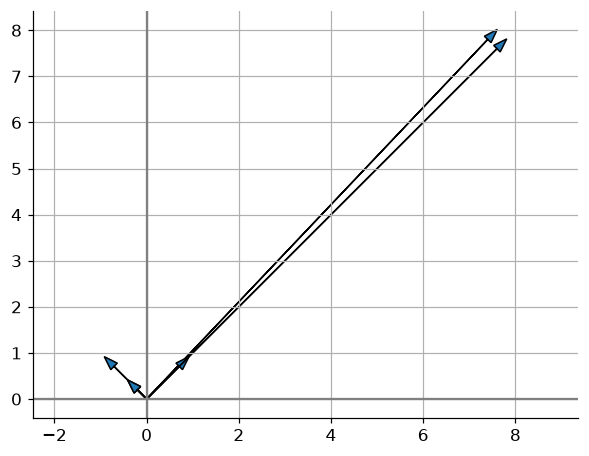

In [114]:
# Задача 3б.
plt.arrow(0,0,vec[0],vec[1],head_width=0.2)
plt.arrow(0,0,d[0],d[1],head_width=0.2)
plt.arrow(0,0,q[0],q[1],head_width=0.2)
plt.arrow(0,0,u[0],u[1],head_width=0.2)
plt.arrow(0,0,p_q[0],p_q[1],head_width=0.2)
plt.arrow(0,0,p_u[0],p_u[1],head_width=0.2)
plt.axhline(0, color="gray")
plt.axvline(0, color="gray")
plt.axis("equal")
plt.grid()
plt.show()


## 4. Дължини, стандартни отклонения и ъгли

Връщаме се към всички $n$ вина. Колона $j$ на $Z$ е векторът на отклоненията $\mathbf d_j$. Дефинираме единичния вектор $\mathbf u_j=\mathbf d_j/\|\mathbf d_j\|$. Тогава

$$\|\mathbf d_j\|=\sqrt{n-1}\,s_j,\qquad
r_{jk}=\mathbf u_j^\top\mathbf u_k=\cos\theta_{jk},\qquad
\theta_{jk}=\arccos(r_{jk}).$$

Ако $U$ съдържа колоните $\mathbf u_j$, то $R=U^\top U$.

**Задача 4а.** Пресметнете дължините на колоните на $Z$, образувайте $U$ и проверете формулите. Намерете ъглите на фиксираната киселинност с плътността, pH и алкохола. Използвайте `np.clip(r, -1, 1)` преди `np.arccos` и `np.degrees` за превръщане в градуси.

In [ ]:
# Задача 4а

**Задача 4б. Визуализация.** Два единични вектора с корелация $r$ имат равнинно представяне

$$\mathbf a=(1,0)^\top,\qquad
\mathbf b=(r,\sqrt{1-r^2})^\top.$$

То запазва нормите, скаларното произведение и ъгъла на първоначалните $n$-мерни вектори. Начертайте трите двойки от задача 4а в отделни панели. Добавете единична окръжност и означете ъгъла. Дъга с радиус $\rho$ се задава с $(\rho\cos t,\rho\sin t)$ за $0\leq t\leq\theta$.

In [ ]:
# Задача 4б

## 5. Обобщена дисперсия и обем

Обобщената извадъчна дисперсия е $\det(S)$. За $D=\operatorname{diag}(s_1,\ldots,s_p)$ имаме

$$S=DRD,\qquad \det(S)=\det(R)\prod_{j=1}^p s_j^2.$$

Матрицата $G=Z^\top Z$ е матрица на Грам на векторите на отклоненията. Обемът $V$ на успоредника за $p=2$, паралелепипеда за $p=3$ или съответната $p$-мерна фигура удовлетворява

$$V^2=\det(G)=(n-1)^p\det(S).$$

За единичните вектори матрицата на Грам е $R$ и квадратът на обема е $\det(R)$. При два единични вектора лицето е $A=\sqrt{1-r^2}$. В общия случай $0\leq\det(R)\leq1$.

**Задача 5а.** Пресметнете $\det(S),\det(R)$ и $V$. Проверете връзката между детерминантите. За първите две колони на $U$ проверете, че лицето, получено от матрицата на Грам, е $\sqrt{1-r_{12}^2}$. Малка стойност на $\det(S)$ сама по себе си не доказва почти линейна зависимост, защото зависи от мерните единици.

In [ ]:
# Задача 5а

**Задача 5б. Визуализация.** Използвайте равнинните вектори $\mathbf a,\mathbf b$ от задача 4б за фиксираната киселинност и pH. Оцветете успоредника с върхове $\mathbf0,\mathbf a,\mathbf a+\mathbf b,\mathbf b$. До него начертайте случая $\mathbf b=\mathbf a$, при който лицето е нула. Посочете лицето във всеки панел. Използвайте `ax.fill` и еднакъв мащаб по осите.

In [ ]:
# Задача 5б

## 6. Промяна на началото, мащаба и броя на колоните

Нека $x'_{ij}=c_jx_{ij}+b_j$, където $c_j>0$, и $C=\operatorname{diag}(c_1,\ldots,c_p)$. Тогава

$$S'=CSC,\qquad \det(S')=\det(S)\prod_{j=1}^p c_j^2,\qquad R'=R.$$

Константите $b_j$ не променят ковариациите. При добавяне на точно копие на колона новите колони са линейно зависими и детерминантите на двете матрици са нула. Рангът е броят линейно независими колони; за центрираната матрица $\operatorname{rank}(Z)\leq\min(p,n-1)$.

**Задача 6а.** Използвайте отделно копие на `data` за всеки случай: умножете плътността по $1000$; добавете $1$ към плътността; добавете копие на плътността като пета колона. Съставете таблица с броя колони, ранга на центрираната матрица и двете детерминанти. Проверете предсказаните промени. При линейна зависимост числената детерминанта може да е малка ненулева стойност поради закръгляване.

In [ ]:
# Задача 6а

**Задача 6б. Визуализация.** В три панела начертайте алкохола спрямо плътността: преди промяната, след умножение по $1000$ и след добавяне на $1$. Надпишете осите с преобразуваните величини. Сравнете подредбата на точките и числата по хоризонталните оси.

In [ ]:
# Задача 6б

## 7. Стандартизация

Стандартизираната матрица $W$ се определя чрез

$$w_{ij}=\frac{x_{ij}-\bar x_j}{s_j}.$$

Всяка колона има средна стойност $0$, извадъчно стандартно отклонение $1$ и дължина $\sqrt{n-1}$. Следователно

$$\frac{W^\top W}{n-1}=R,\qquad W=\sqrt{n-1}\,U.$$

Стандартизацията не превръща произволно разпределение в нормално.

**Задача 7а.** Пресметнете $W$ и проверете посочените свойства. Обяснете разликата между стандартизиране на колона и нормализиране до единична дължина.

In [ ]:
# Задача 7а

**Задача 7б. Визуализация.** Начертайте хистограми на четирите стандартизирани колони с обща хоризонтална скала. Означете $0$ с плътна вертикална линия и $-1,1$ с пунктир. Сравнете формите на разпределенията.

In [ ]:
# Задача 7б

## 8. Връзка с линейната регресия

Нека $F\in\mathbb R^{n\times k}$ съдържа всичките $k=11$ физикохимични показателя, а $\mathbf y$ — стойностите на `quality`. Използваме метода на най-малките квадрати (OLS). Оценката `quality` е дискретна и линейният модел служи като числово приближение.

За колона $j$ на $F$ означаваме средната стойност с $\mu_j$ и извадъчното стандартно отклонение с $t_j$. Дефинираме $F^*_{ij}=(F_{ij}-\mu_j)/t_j$, $X=[\mathbf1,F]$ и $B=[\mathbf1,F^*]$. При пълен ранг на колоните

$$\hat{\boldsymbol\beta}
=\underset{\boldsymbol\beta}{\arg\min}\|\mathbf y-X\boldsymbol\beta\|^2
=(X^\top X)^{-1}X^\top\mathbf y,\qquad
\hat{\mathbf y}=X\hat{\boldsymbol\beta},\qquad
\mathbf e=\mathbf y-\hat{\mathbf y},\qquad X^\top\mathbf e=\mathbf0.$$

За стандартизирания модел означаваме коефициентите с $\hat{\boldsymbol\gamma}$. Двете параметризации са свързани чрез

$$\hat\beta_j=\frac{\hat\gamma_j}{t_j}\ (j\geq1),\qquad
\hat\beta_0=\hat\gamma_0-\sum_{j=1}^k\mu_j\frac{\hat\gamma_j}{t_j},\qquad
A\hat{\boldsymbol\beta}=B\hat{\boldsymbol\gamma}.$$

**Задача 8а.** Постройте $X$ и $B$ и оценете двата модела с `np.linalg.lstsq`. Сравнете оценените стойности и проверете връзката между коефициентите. Проверете $B^\top\mathbf e\approx\mathbf0$ с абсолютен толеранс $10^{-8}$. Обяснете защо стандартизацията запазва проекцията на $\mathbf y$ върху пространството на колоните на модела.

In [ ]:
# Задача 8а

**Задача 8б. Визуализация.** В първи панел начертайте оценените стойности от стандартизирания модел спрямо тези от първоначалния модел и добавете правата $y=x$. Във втори панел начертайте остатъците спрямо оценените стойности и добавете хоризонталната права $e=0$.

In [ ]:
# Задача 8б